# TwinGuard-SD-IoT — data, models, and forecast evaluation

Data pipeline, exploratory analysis, model training, and forecast evaluation for the paper
*TwinGuard-SD-IoT: A Fidelity-Aware GNN Digital Twin and Agentic AI Framework for Proactive QoS Assurance in Software-Defined IoT Networks*.
The TwinGuard safety engine itself (conformal bounds, fidelity score, gate) is evaluated in `TwinGuard_gate.ipynb`.

**Data.** Zenodo dataset 10.5281/zenodo.17255307 (CC-BY 4.0), downloaded, checksum-verified, and cleaned by the setup cell
(D2 restricted to its genuine 1–2 July 2025 records; see `results/02_integrity_checks.txt`).

**Sections**
0. Setup (data download, checksum verification, cleaning)
1. Load cleaned data
2. Exploratory data analysis
3. Graph data pipeline (15 s grid, line graph, masks, splits); 3b. summary statistics and figures of the data analysis
4. Models: per-link GRU (B2) and GNN twin, hyperparameter search, five final runs each, predictions on every split
5. Forecast evaluation (Table 4 of the paper), training curves, hyperparameter search
6. Package outputs, then inference cost per decision epoch (Section 6.7)

Runs on Kaggle (GPU, about 30 min) or locally; see the run configuration below.

## Run configuration
Edit this cell only. The notebook detects automatically whether it runs on **Kaggle** or locally, and uses a **GPU** when one is available.

**On Kaggle:** upload the folder `data/processed/` (files `D1.csv`, `D2.csv`, `D3.csv`) as a Kaggle Dataset and add it to the notebook
(*Add Input*); enable a GPU under *Settings → Accelerator*. All outputs are written to `/kaggle/working/` and zipped at the end
(`twinguard_outputs.zip`, downloadable from the *Output* panel).

In [1]:
# ===== Run configuration =====
SMOKE = False                 # True: tiny run (1 epoch, 2 trials, 1 seed) in results_smoke/ to check that every cell runs

# Hyperparameter search (validation slice only; never the test splits). Both learned models get the SAME
# configurations and the same training procedure, so the comparison is fair.
TUNE = True
N_TRIALS = 16                 # configurations per model (trial 0 = BASE_HP)
SEARCH_SPACE = dict(hidden=[32, 64, 96], layers=[1, 2, 3], heads=[2, 4], gru=[64, 128], gru_layers=[1, 2],
                    dropout=[0.0, 0.1, 0.2], lr=[3e-4, 1e-3, 2e-3, 3e-3], batch=[64, 128, 256],
                    wd=[1e-6, 1e-5, 1e-4])
BASE_HP = dict(hidden=32, layers=2, heads=2, gru=64, gru_layers=1, dropout=0.0, lr=1e-3, batch=64, wd=1e-5)
FIXED = dict(max_epochs=150, patience=15, lr_patience=5, lr_factor=0.5, clip=1.0)   # early stopping + LR schedule

SEEDS = [0, 1, 2, 3, 4]       # final models per class; the GNN-twin seeds form the ensemble
N_BOOT = 300                  # bootstrap resamples for confidence intervals

if SMOKE:
    SEEDS = [0]; N_TRIALS = 2; FIXED.update(max_epochs=1)

## 0. Setup

In [2]:
import os, sys, json, time, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import torch

# ---- data: use cleaned files if present, otherwise download from Zenodo, verify, and clean
import csv, hashlib, urllib.request
from IPython.display import display

ZENODO_RECORD = "17255307"                    # doi:10.5281/zenodo.17255307, CC-BY 4.0
RAW_FILES = {"D1": "dataset_01_TC33_27062025_labeled.csv",
             "D2": "dataset_02_TC33_02072025_labeled.csv",
             "D3": "dataset_03_TC33_05072025_labeled.csv"}
D2_START = 1751328000                         # 2025-07-01 00:00 UTC; earlier D2 records duplicate D1

def has_data(d):
    return d is not None and all((Path(d) / f"{s}.csv").exists() for s in RAW_FILES)

def prepare_data(out_dir, raw_dir):
    out_dir, raw_dir = Path(out_dir), Path(raw_dir)
    if has_data(out_dir):
        return out_dir
    out_dir.mkdir(parents=True, exist_ok=True); raw_dir.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(f"https://zenodo.org/api/records/{ZENODO_RECORD}", timeout=60) as r:
        md5 = {f["key"]: f["checksum"].split(":")[1] for f in json.load(r)["files"]}
    for s, name in RAW_FILES.items():
        raw = raw_dir / name
        if not raw.exists():
            print("downloading", name, flush=True)
            urllib.request.urlretrieve(f"https://zenodo.org/api/records/{ZENODO_RECORD}/files/{name}/content", raw)
        assert hashlib.md5(raw.read_bytes()).hexdigest() == md5[name], f"checksum mismatch: {name}"
        with open(raw, encoding="utf-8", newline="") as f:
            reader = csv.DictReader(f); cols, rows = reader.fieldnames, list(reader)
        n_raw = len(rows)
        if s == "D2":
            rows = [r for r in rows if int(r["timestamp"]) >= D2_START]
        assert len({(r["timestamp"], r["link"]) for r in rows}) == len(rows), f"{s}: duplicates remain"
        with open(out_dir / f"{s}.csv", "w", encoding="utf-8", newline="") as f:
            w = csv.DictWriter(f, fieldnames=cols); w.writeheader(); w.writerows(rows)
        print(f"{s}: checksum OK, {n_raw} -> {len(rows)} records", flush=True)
    return out_dir

KAGGLE_WORK, KAGGLE_INPUT = Path("/kaggle/working"), Path("/kaggle/input")
KAGGLE = KAGGLE_WORK.exists()
if KAGGLE:
    ROOT = KAGGLE_WORK                                              # writable
    uploaded = [p.parent for p in sorted(KAGGLE_INPUT.rglob("D1.csv"))] if KAGGLE_INPUT.exists() else []
    uploaded = [d for d in uploaded if has_data(d)]
    DATA = uploaded[0] if uploaded else prepare_data(ROOT / "data" / "processed", ROOT / "data" / "raw")
    PROC_OUT = ROOT
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA = prepare_data(ROOT / "data" / "processed", ROOT / "data" / "zenodo_17255307")
    PROC_OUT = DATA
RES = ROOT / ("results_smoke" if SMOKE else "results")
FIG = RES / "figs"                                                  # exploratory figures
FIG.mkdir(parents=True, exist_ok=True); PROC_OUT.mkdir(parents=True, exist_ok=True)

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count()))                   # physical cores; measured faster than all threads
else:
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False

# Paper style: black and white, serif, no chart junk
mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "legend.fontsize": 8, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300,
    "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False,
})
GRAYS = {"D1": "0.0", "D2": "0.45", "D3": "0.7"}
STYLES = {"D1": "-", "D2": "--", "D3": ":"}

print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {mpl.__version__} | torch {torch.__version__} | threads {torch.get_num_threads()}")
print("environment:", "Kaggle" if KAGGLE else "local", "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "", "| smoke run" if SMOKE else "")
print("data:", DATA, "| outputs:", RES)

downloading dataset_01_TC33_27062025_labeled.csv
D1: checksum OK, 177092 -> 177092 records
downloading dataset_02_TC33_02072025_labeled.csv
D2: checksum OK, 157594 -> 45904 records
downloading dataset_03_TC33_05072025_labeled.csv
D3: checksum OK, 167885 -> 167885 records
python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | matplotlib 3.10.0 | torch 2.11.0+cu128 | threads 2
environment: Kaggle | device: cuda (Tesla T4) 
data: /kaggle/working/data/processed | outputs: /kaggle/working/results


## 1. Load cleaned data
`avalability` (sic, dataset spelling) is constant (= 1) in every measured record and is dropped.
A record is *missing* when all metrics are empty; partially filled records do not occur.

In [3]:
SCEN = ["D1", "D2", "D3"]
METRICS = ["rtt", "jitter", "packet_loss", "outflow_Router", "inflow_Router", "ttl", "resolve", "probe_duration"]
RTT_MAX, PLR_MAX = 10.0, 1.0   # SLA budgets (ms, %) chosen in the paper

raw = {}
for s in SCEN:
    df = pd.read_csv(DATA / f"{s}.csv")
    allm = METRICS + ["avalability"]
    df["missing"] = df[allm].isna().all(axis=1)
    assert (df[allm].isna().any(axis=1) == df["missing"]).all(), "partially missing records"
    assert df.loc[~df.missing, "avalability"].eq(1.0).all(), "availability not constant"
    df["violation"] = np.where(df.missing, np.nan,
                               ((df.rtt > RTT_MAX) | (df.packet_loss > PLR_MAX)).astype(float))
    raw[s] = df

rows = []
for s, df in raw.items():
    m = df[~df.missing]
    lab = m.LABEL.value_counts(normalize=True).mul(100)
    rows.append({"scenario": s, "records": len(df), "measured": len(m),
                 "missing %": 100 * df.missing.mean(), "label0 %": lab.get(0.0, 0),
                 "label1 %": lab.get(1.0, 0), "label2 %": lab.get(2.0, 0),
                 "SLA viol. %": 100 * m.violation.mean(),
                 "RTT p50": m.rtt.median(), "RTT p95": m.rtt.quantile(.95)})
summary = pd.DataFrame(rows).set_index("scenario").round(2)
summary

,records,measured,missing %,label0 %,label1 %,label2 %,SLA viol. %,RTT p50,RTT p95
scenario,,,,,,,,,
D1,177092,143571,18.93,97.77,2.17,0.06,1.70,1.20,2.92
D2,45904,36440,20.62,71.99,27.09,0.93,31.54,1.89,31.25
D3,167885,130820,22.08,94.69,5.23,0.08,5.21,1.49,6.65


## 2. Exploratory data analysis

### 2.1 RTT and jitter distributions per scenario

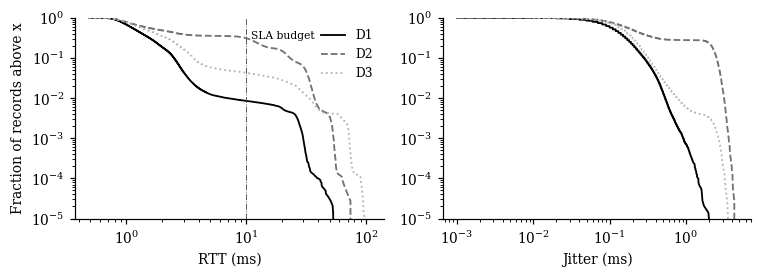

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6))
for s, df in raw.items():
    m = df[~df.missing]
    for ax, col, lab in [(axes[0], "rtt", "RTT (ms)"), (axes[1], "jitter", "Jitter (ms)")]:
        x = np.sort(m[col].values); y = 1 - np.arange(1, len(x) + 1) / len(x)
        ax.plot(np.maximum(x, 1e-3), y, color=GRAYS[s], ls=STYLES[s], lw=1.2, label=s)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(lab); ax.set_ylim(1e-5, 1)
axes[0].axvline(RTT_MAX, color="0.3", lw=0.6, ls="-."); axes[0].text(RTT_MAX*1.1, 0.3, "SLA budget", fontsize=7)
axes[0].set_ylabel("Fraction of records above x"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "eda_ccdf_rtt_jitter.png"); plt.show()

### 2.2 How each scenario evolves over time (hourly p95 RTT, SLA-violation share, missing share)

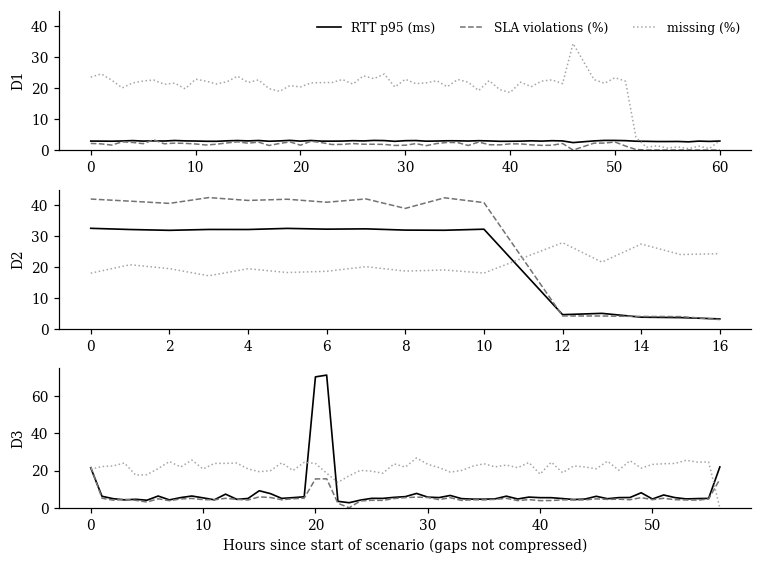

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(7, 5.2), sharex=False)
for ax, s in zip(axes, SCEN):
    df = raw[s].copy()
    df["hour"] = (df.timestamp - df.timestamp.min()) // 3600
    g = df.groupby("hour")
    meas = df[~df.missing].groupby("hour")
    p95 = meas.rtt.quantile(.95)
    vio = 100 * meas.violation.mean()
    mis = 100 * g.missing.mean()
    ax.plot(p95.index, p95.values, color="0", lw=1.1, label="RTT p95 (ms)")
    ax.plot(vio.index, vio.values, color="0.45", lw=1.0, ls="--", label="SLA violations (%)")
    ax.plot(mis.index, mis.values, color="0.65", lw=1.0, ls=":", label="missing (%)")
    ax.set_ylabel(s); ax.set_ylim(0, max(45, p95.max() * 1.05))
axes[0].legend(ncol=3, loc="upper right"); axes[-1].set_xlabel("Hours since start of scenario (gaps not compressed)")
fig.tight_layout(); fig.savefig(FIG / "eda_time_course.png"); plt.show()

### 2.3 Missing measurements by link: missingness is load-dependent

In [6]:
LINKS = sorted(raw["D1"].link.unique())
tab = pd.DataFrame({s: raw[s].groupby("link").missing.mean().mul(100) for s in SCEN}).loc[LINKS]
load = pd.DataFrame({s: raw[s][~raw[s].missing].groupby("link").outflow_Router.quantile(.95) for s in SCEN}).loc[LINKS]
display(pd.concat({"missing %": tab.round(1), "outflow p95 (Mbps)": load.round(1)}, axis=1))

# Is a link more likely to be missing right after high load?  (D1, loaded links)
d = raw["D1"].sort_values(["link", "timestamp"]).copy()
d["prev_out"] = d.groupby("link").outflow_Router.ffill().groupby(d.link).shift(1)
d["load_bin"] = pd.cut(d.prev_out, [0, 10, 40, 70, 90, 200], labels=["0-10", "10-40", "40-70", "70-90", ">90"])
print("D1: P(missing | last observed outflow), %")
print((100 * d.groupby("load_bin", observed=True).missing.mean()).round(1).to_string())

missing %             outflow p95 (Mbps)            
             D1    D2    D3                 D1    D2    D3
link                                                      
R1-R2      31.4  36.9  37.3               81.6  78.9  85.3
R1-R9      19.6  27.5  24.1               80.3  80.7  82.0
R2-R3      33.2  30.9  38.1               80.7  70.7  83.6
R2-R9       0.6   0.9   0.8                4.7   4.7   4.7
R3-R4      36.0  36.8  39.6               79.8  78.2  81.7
R3-R8       0.6   2.3   1.1                4.7   4.7   4.7
R4-R5      18.8  17.1  24.9               87.1  81.7  87.0
R4-R6       0.6   0.9   1.8                4.7   4.7   4.7
R6-R5      54.6  63.0  61.0                4.6   4.6   4.6
R7-R6       0.6   1.0   1.0                4.6   4.6   4.6
R8-R6      16.8  15.8  20.3               74.1  76.3  75.9
R8-R7       0.8   0.8   1.1                4.7   4.7   4.7
R9-R8      35.0  35.9  37.9               78.2  70.3  79.4

D1: P(missing | last observed outflow), %
load_bin
0-10     13.2
10-40    36.0
40-70    43.0
70-90    44.6
>90      57.7


### 2.4 Load versus QoS: where does congestion start? (D1, loaded links)

,n,RTT p50,RTT p95,loss mean %,SLA viol. %
ob,,,,,
"(0, 10]",123203,1.18,2.78,0.01,0.21
"(10, 20]",3753,1.09,2.70,0.10,2.37
"(20, 30]",2268,1.10,2.79,0.16,3.62
"(30, 40]",2089,1.17,3.18,0.20,4.55
"(40, 50]",2420,1.22,3.55,0.19,4.38
"(50, 60]",1985,1.34,5.05,0.29,7.66
"(60, 70]",2129,1.47,7.22,0.30,8.69
"(70, 80]",2209,1.63,14.61,0.38,11.54
"(80, 90]",2276,2.04,27.70,0.75,28.51


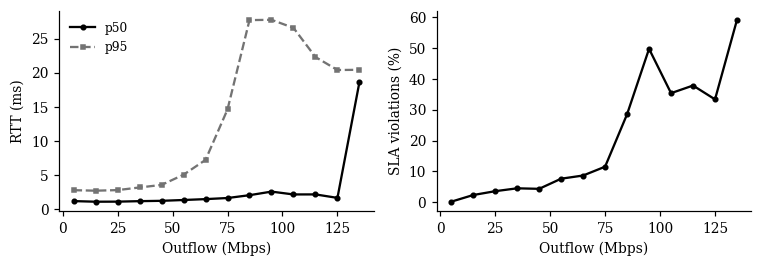

In [7]:
m = raw["D1"][~raw["D1"].missing].copy()
bins = np.arange(0, 150, 10)
m["ob"] = pd.cut(m.outflow_Router, bins)
g = m.groupby("ob", observed=True)
stats = pd.DataFrame({"n": g.size(), "RTT p50": g.rtt.median(), "RTT p95": g.rtt.quantile(.95),
                      "loss mean %": g.packet_loss.mean(), "SLA viol. %": 100 * g.violation.mean()})
display(stats.round(2))

fig, ax = plt.subplots(1, 2, figsize=(7, 2.5))
mid = [b.mid for b in stats.index]
ax[0].plot(mid, stats["RTT p50"], "-o", color="0", ms=3, label="p50")
ax[0].plot(mid, stats["RTT p95"], "--s", color="0.45", ms=3, label="p95")
ax[0].set_xlabel("Outflow (Mbps)"); ax[0].set_ylabel("RTT (ms)"); ax[0].legend()
ax[1].plot(mid, stats["SLA viol. %"], "-o", color="0", ms=3)
ax[1].set_xlabel("Outflow (Mbps)"); ax[1].set_ylabel("SLA violations (%)")
fig.tight_layout(); fig.savefig(FIG / "eda_load_vs_qos.png"); plt.show()

### 2.5 Do the dataset labels agree with our SLA definition?

In [8]:
for s in SCEN:
    m = raw[s][~raw[s].missing]
    ct = pd.crosstab(m.LABEL, m.violation.map({0.0: "SLA ok", 1.0: "SLA violated"}), normalize="index").mul(100).round(1)
    print(f"--- {s} (row %: share of each label that violates our SLA)"); print(ct.to_string())

--- D1 (row %: share of each label that violates our SLA)
violation  SLA ok  SLA violated
LABEL                          
0.0          99.9           0.1
1.0          27.7          72.3
2.0           0.0         100.0
--- D2 (row %: share of each label that violates our SLA)
violation  SLA ok  SLA violated
LABEL                          
0.0          91.7           8.3
1.0           8.9          91.1
2.0           0.0         100.0
--- D3 (row %: share of each label that violates our SLA)
violation  SLA ok  SLA violated
LABEL                          
0.0          99.3           0.7
1.0          14.6          85.4
2.0           0.0         100.0


### 2.6 Predictability: autocorrelation of RTT per link (D1, measured steps)
High lag-1 autocorrelation means persistence is a strong baseline; fast decay means forecasting is hard.

In [9]:
def acf(x, lags):
    x = x - np.nanmean(x); v = np.nanmean(x * x)
    return [np.nanmean(x[k:] * x[:-k]) / v for k in lags]

lags = [1, 2, 4, 8, 20, 40]
d1 = raw["D1"].sort_values("timestamp")
rows = {}
for l in LINKS:
    x = d1.loc[d1.link == l, "rtt"].values.astype(float)
    rows[l] = acf(np.log1p(x), lags)
ac = pd.DataFrame(rows, index=[f"lag {k} ({15*k}s)" for k in lags]).T.round(2)
ac

,lag 1 (15s),lag 2 (30s),lag 4 (60s),lag 8 (120s),lag 20 (300s),lag 40 (600s)
R1-R2,0.26,0.19,0.07,-0.00,-0.01,0.02
R1-R9,0.28,0.20,0.09,0.00,-0.01,-0.01
R2-R3,0.36,0.25,0.11,-0.00,-0.00,-0.01
R2-R9,0.19,0.12,0.05,-0.02,-0.02,0.00
R3-R4,0.20,0.13,0.06,0.02,-0.00,0.00
R3-R8,0.20,0.14,0.06,-0.01,-0.02,-0.01
R4-R5,0.18,0.10,0.06,-0.01,0.01,-0.01
R4-R6,0.15,0.12,0.06,-0.00,-0.02,-0.01
R6-R5,0.14,0.09,0.02,0.01,-0.03,0.01
R7-R6,0.27,0.23,0.10,0.00,-0.01,-0.01


## 3. Graph data pipeline
* **Grid.** One snapshot every 15 s. A gap of more than 300 s starts a new segment; shorter gaps are filled with missing steps.
* **Graph.** Line graph of the router topology: each of the 13 links is a node; two links are adjacent if they share a router.
* **Features per link** (8 metrics + 2 indicators): `log1p` of RTT, jitter, loss, outflow, inflow, resolve, probe duration; TTL; observed flag; steps since last observation (capped at 20, scaled to [0,1]).
  Missing metrics are forward-filled from the last observation of the same link, then standardized with training statistics.
* **Targets.** RTT, jitter, loss at horizons Δ ∈ {1, 2, 4} steps (15, 30, 60 s), with a mask; SLA violation flag.
* **Splits (chronological).** D1 segment 1 → train 60 % / calibration 20 % / test 20 %; D1 segment 2 (quiet) reported separately; D2 and D3 test only.

In [10]:
STEP, MAXGAP, W, HORIZONS = 15, 300, 20, (1, 2, 4)
ROUTERS = sorted({r for l in LINKS for r in l.split("-")}, key=lambda r: int(r[1:]))
L = len(LINKS)

# line-graph adjacency (with self-loops)
A = np.eye(L, dtype=np.float32)
for i, a in enumerate(LINKS):
    for j, b in enumerate(LINKS):
        if i != j and set(a.split("-")) & set(b.split("-")):
            A[i, j] = 1.0
print(f"{len(ROUTERS)} routers, {L} links, line-graph edges (undirected) = {int((A.sum() - L) / 2)}")
print("mean degree in line graph:", round(float((A.sum(1) - 1).mean()), 2))

def to_grid(df):
    # Returns list of segments: dict(ts, V[T,L,M] raw metrics with NaN, lab[T,L], vio[T,L]).
    ts_all = np.sort(df.timestamp.unique())
    cuts = np.where(np.diff(ts_all) > MAXGAP)[0]
    bounds = np.split(ts_all, cuts + 1)
    segs = []
    for b in bounds:
        grid = np.arange(b[0], b[-1] + 1, STEP)
        off = (b - b[0]) % STEP
        assert (off == 0).all(), "timestamps not aligned to the 15 s grid"
        sub = df[(df.timestamp >= b[0]) & (df.timestamp <= b[-1])]
        idx = pd.MultiIndex.from_product([grid, LINKS], names=["timestamp", "link"])
        p = sub.set_index(["timestamp", "link"]).reindex(idx)
        V = p[METRICS].to_numpy(np.float32).reshape(len(grid), L, len(METRICS))
        lab = p["LABEL"].to_numpy(np.float32).reshape(len(grid), L)
        vio = p["violation"].to_numpy(np.float32).reshape(len(grid), L)
        segs.append({"ts": grid, "V": V, "lab": lab, "vio": vio})
    return segs

GRID = {s: to_grid(raw[s]) for s in SCEN}
for s, segs in GRID.items():
    for k, g in enumerate(segs):
        obs = ~np.isnan(g["V"][..., 0])
        print(f"{s} seg{k}: {len(g['ts'])} steps ({len(g['ts'])*STEP/3600:.1f} h), observed {100*obs.mean():.1f}%, "
              f"SLA viol. {100*np.nanmean(g['vio']):.2f}%")

9 routers, 13 links, line-graph edges (undirected) = 27
mean degree in line graph: 4.15
D1 seg0: 11059 steps (46.1 h), observed 76.1%, SLA viol. 2.04%
D1 seg1: 2881 steps (12.0 h), observed 91.2%, SLA viol. 0.60%
D2 seg0: 2620 steps (10.9 h), observed 78.9%, SLA viol. 41.33%
D2 seg1: 1012 steps (4.2 h), observed 72.7%, SLA viol. 4.04%
D3 seg0: 5532 steps (23.1 h), observed 75.8%, SLA viol. 6.15%
D3 seg1: 7677 steps (32.0 h), observed 76.5%, SLA viol. 4.53%


In [11]:
# chronological splits
d1a = GRID["D1"][0]
T = len(d1a["ts"]); i_tr, i_ca = int(0.6 * T), int(0.8 * T)
SPLITS = {
    "train":    [{k: (v[:i_tr] if k != "ts" else v[:i_tr]) for k, v in d1a.items()}],
    "cal":      [{k: v[i_tr:i_ca] for k, v in d1a.items()}],
    "test_D1":  [{k: v[i_ca:] for k, v in d1a.items()}],
    "D1_quiet": GRID["D1"][1:],
    "D2":       GRID["D2"],
    "D3":       GRID["D3"],
}

# feature engineering: log1p on heavy-tailed metrics, standardize with TRAIN stats
LOGCOLS = [METRICS.index(c) for c in ["rtt", "jitter", "packet_loss", "outflow_Router", "inflow_Router", "resolve", "probe_duration"]]
def transform(V):
    Z = V.copy()
    Z[..., LOGCOLS] = np.log1p(np.clip(Z[..., LOGCOLS], 0, None))
    return Z

tr = transform(SPLITS["train"][0]["V"]).reshape(-1, len(METRICS))
MU = np.nanmean(tr, 0); SD = np.nanstd(tr, 0) + 1e-6

def features(seg):
    V = seg["V"]; Tn = len(V)
    obs = ~np.isnan(V[..., 0])
    Z = (transform(V) - MU) / SD
    Zf = pd.DataFrame(Z.reshape(Tn, -1)).ffill().to_numpy().reshape(Z.shape)   # last observation, per link & metric
    Zf = np.nan_to_num(Zf, nan=0.0)                                              # never observed yet -> train mean
    age = np.zeros((Tn, L), np.float32); run = np.zeros(L, np.float32)
    for t in range(Tn):
        run = np.where(obs[t], 0, np.minimum(run + 1, 20)); age[t] = run
    X = np.concatenate([Zf, obs[..., None].astype(np.float32), (age / 20.0)[..., None]], axis=-1)
    return X.astype(np.float32), obs

TGT = [METRICS.index(c) for c in ["rtt", "jitter", "packet_loss"]]
def windows(seg, X, obs):
    # Index arrays for all windows [t-W+1, t] with targets at t+Δ for every Δ in HORIZONS.
    Tn = len(X); hmax = max(HORIZONS)
    t_end = np.arange(W - 1, Tn - hmax)
    Y = np.stack([seg["V"][t_end + h][..., TGT] for h in HORIZONS], 1)        # [N, H, L, 3] raw units
    Ym = np.stack([obs[t_end + h] for h in HORIZONS], 1)                       # [N, H, L]
    Vio = np.stack([seg["vio"][t_end + h] for h in HORIZONS], 1)               # [N, H, L]
    Lab = np.stack([seg["lab"][t_end + h] for h in HORIZONS], 1)
    return {"t_end": t_end, "Y": Y, "Ym": Ym, "vio": Vio, "lab": Lab}

DS = {}
for name, segs in SPLITS.items():
    parts = []
    for seg in segs:
        X, obs = features(seg)
        w = windows(seg, X, obs)
        parts.append({"X": X, "obs": obs, "ts": seg["ts"], "V": seg["V"], **w})
    DS[name] = parts

print(f"{'split':10s} {'windows':>8s} {'target obs %':>13s} {'SLA viol. % (Δ=1)':>18s} {'label1+2 % (Δ=1)':>17s}")
for name, parts in DS.items():
    n = sum(len(p["t_end"]) for p in parts)
    ym = np.concatenate([p["Ym"][:, 0] for p in parts]); vio = np.concatenate([p["vio"][:, 0] for p in parts])
    lab = np.concatenate([p["lab"][:, 0] for p in parts])
    print(f"{name:10s} {n:8d} {100*ym.mean():13.1f} {100*np.nanmean(vio):18.2f} {100*np.nanmean(lab >= 1):17.2f}")
print("feature tensor per window:", (W, L, DS['train'][0]['X'].shape[-1]))

split       windows  target obs %  SLA viol. % (Δ=1)  label1+2 % (Δ=1)
train          6612          76.9               2.17              2.17
cal            2189          76.4               1.88              1.93
test_D1        2189          73.5               1.85              1.86
D1_quiet       2858          91.4               0.59              0.66
D2             3586          77.3              31.64             21.73
D3            13163          76.2               5.17              4.02
feature tensor per window: (20, 13, 10)


In [12]:
# save the pipeline output so later sections (and scripts) can reuse it
np.savez_compressed(PROC_OUT / "graph_pipeline.npz",
                    A=A, LINKS=np.array(LINKS), MU=MU, SD=SD, W=W, HORIZONS=np.array(HORIZONS),
                    **{f"{n}_{k}_{i}": p[k] for n, parts in DS.items() for i, p in enumerate(parts)
                       for k in ["X", "obs", "ts", "V", "t_end", "Y", "Ym", "vio", "lab"]})
print("saved", PROC_OUT / "graph_pipeline.npz", f"({(PROC_OUT / 'graph_pipeline.npz').stat().st_size/1e6:.1f} MB)")

saved /kaggle/working/graph_pipeline.npz (7.4 MB)


## 3b. Summary statistics and figures of the data analysis
Figures are saved to `results/figs/`; every number of the data analysis is saved to `results/data_stats.json`
and printed below.

In [13]:
PAPER_W = 4.75   # inches, Springer text width
mpl.rcParams['mathtext.fontset'] = 'cm'   # math in the same serif family as the text
STATS = {}

# ---- scenario summary (Table 3) --------------------------------------------
STATS["scenarios"] = {}
for s, df in raw.items():
    m = df[~df.missing]
    ts = np.sort(df.timestamp.unique()); gaps = np.diff(ts)
    lab = m.LABEL.value_counts(normalize=True).mul(100)
    STATS["scenarios"][s] = {
        "records": int(len(df)), "measured_records": int(len(m)),
        "measured_hours": round(float(gaps[gaps <= MAXGAP].sum() / 3600), 1),
        "missing_pct": round(100 * float(df.missing.mean()), 1),
        "label_pct": {str(int(k)): round(float(v), 2) for k, v in lab.sort_index().items()},
        "rtt_p50_p95_p99": [round(float(m.rtt.quantile(q)), 2) for q in (.5, .95, .99)],
        "jitter_p50_p95": [round(float(m.jitter.quantile(q)), 2) for q in (.5, .95)],
        "loss_mean_p99": [round(float(m.packet_loss.mean()), 2), round(float(m.packet_loss.quantile(.99)), 2)],
        "sla_violation_pct": round(100 * float(m.violation.mean()), 2),
    }
pd.DataFrame(STATS["scenarios"]).T

,records,measured_records,measured_hours,missing_pct,label_pct,rtt_p50_p95_p99,jitter_p50_p95,loss_mean_p99,sla_violation_pct
D1,177092,143571,58.1,18.9,"{'0': 97.77, '1': 2.17, '2': 0.06}","[1.2, 2.92, 7.0]","[0.12, 0.36]","[0.05, 1.52]",1.7
D2,45904,36440,15.1,20.6,"{'0': 71.99, '1': 27.09, '2': 0.93}","[1.89, 31.25, 37.11]","[0.2, 2.74]","[0.22, 2.03]",31.54
D3,167885,130820,55.0,22.1,"{'0': 94.69, '1': 5.23, '2': 0.08}","[1.49, 6.65, 33.36]","[0.15, 0.41]","[0.06, 1.83]",5.21


### RTT tail per scenario and the SLA budget

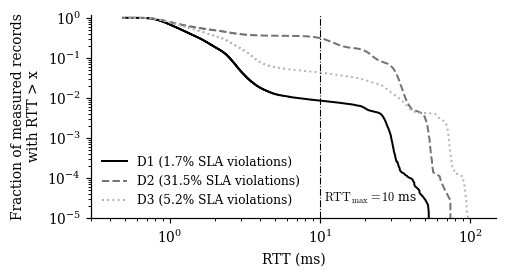

In [14]:
fig, ax = plt.subplots(figsize=(PAPER_W, 2.4))
for s in SCEN:
    x = np.sort(raw[s].loc[~raw[s].missing, "rtt"].values)
    y = 1 - np.arange(1, len(x) + 1) / len(x)
    ax.plot(x, y, color=GRAYS[s], ls=STYLES[s], lw=1.3,
            label=f"{s} ({STATS['scenarios'][s]['sla_violation_pct']:.1f}% SLA violations)")
ax.axvline(RTT_MAX, color="0", lw=0.7, ls="-.")
ax.text(RTT_MAX * 1.07, 2.5e-5, r"$\mathrm{RTT}_{\max} = 10$ ms", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-5, 1.2); ax.set_xlim(0.3, 150)
ax.set_xlabel("RTT (ms)"); ax.set_ylabel("Fraction of measured records\nwith RTT > x")
ax.legend(loc="lower left")
fig.savefig(FIG / "rtt_tail_ccdf.png"); plt.show()

### Time course of each scenario (hourly)

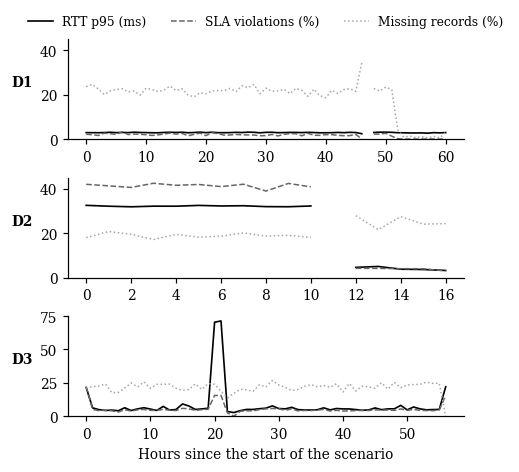

{'D1': {'hours_with_violation_gt15pct': [],
  'max_hourly_rtt_p95': 3.1,
  'max_hourly_violation_pct': 3.3},
 'D2': {'hours_with_violation_gt15pct': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
  'max_hourly_rtt_p95': 32.5,
  'max_hourly_violation_pct': 42.4},
 'D3': {'hours_with_violation_gt15pct': [0, 20, 21, 56],
  'max_hourly_rtt_p95': 71.4,
  'max_hourly_violation_pct': 22.0}}

In [15]:
STATS["events"] = {}
fig, axes = plt.subplots(3, 1, figsize=(PAPER_W, 4.4))
for ax, s in zip(axes, SCEN):
    df = raw[s].copy()
    df["hour"] = (df.timestamp - df.timestamp.min()) // 3600
    g = df.groupby("hour")
    meas = df[~df.missing].groupby("hour")
    p95 = meas.rtt.quantile(.95)
    vio = 100 * meas.violation.mean()
    mis = 100 * g.missing.mean()
    full = np.arange(0, df.hour.max() + 1)          # hours without data -> NaN -> line break
    p95, vio, mis = p95.reindex(full), vio.reindex(full), mis.reindex(full)
    ax.plot(p95.index, p95.values, color="0", lw=1.1, label="RTT p95 (ms)")
    ax.plot(vio.index, vio.values, color="0.4", lw=1.0, ls="--", label="SLA violations (%)")
    ax.plot(mis.index, mis.values, color="0.65", lw=1.0, ls=":", label="Missing records (%)")
    ax.set_ylabel(s, rotation=0, labelpad=12, fontweight="bold")
    ax.set_ylim(0, 75 if s == "D3" else 45)
    hot = vio[vio > 15].dropna()
    STATS["events"][s] = {"hours_with_violation_gt15pct": [int(h) for h in hot.index],
                          "max_hourly_rtt_p95": round(float(p95.max()), 1),
                          "max_hourly_violation_pct": round(float(vio.max()), 1)}
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.35))
axes[-1].set_xlabel("Hours since the start of the scenario")
fig.tight_layout(h_pad=0.6); fig.savefig(FIG / "hourly_time_course.png"); plt.show()
STATS["events"]

### Load dependence of QoS and of missing measurements (D1)

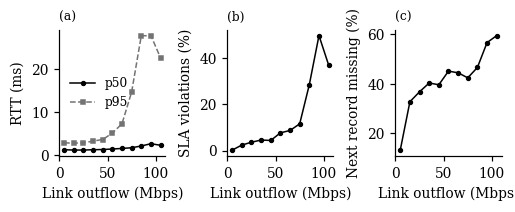

,n,RTT p50,RTT p95,SLA viol. %,P(missing next) %
"(0, 10]",123203,1.18,2.78,0.2,13.2
"(10, 20]",3753,1.09,2.70,2.4,32.8
"(20, 30]",2268,1.10,2.79,3.6,36.8
"(30, 40]",2089,1.17,3.18,4.5,40.3
"(40, 50]",2420,1.22,3.55,4.4,39.6
"(50, 60]",1985,1.34,5.05,7.7,45.1
"(60, 70]",2129,1.47,7.22,8.7,44.5
"(70, 80]",2209,1.63,14.61,11.5,42.4
"(80, 90]",2276,2.04,27.70,28.5,46.6
"(90, 100]",811,2.57,27.75,49.7,56.7


In [16]:
d = raw["D1"].sort_values(["link", "timestamp"]).copy()
d["last_out"] = d.groupby("link").outflow_Router.ffill().groupby(d.link).shift(1)
edges = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150]
d["bin"] = pd.cut(d.last_out, edges)
m = d[~d.missing].copy(); m["obin"] = pd.cut(m.outflow_Router, edges)
qos = m.groupby("obin", observed=True).agg(n=("rtt", "size"), p50=("rtt", "median"),
                                             p95=("rtt", lambda x: x.quantile(.95)),
                                             vio=("violation", "mean"))
mis = d.groupby("bin", observed=True).missing.agg(["mean", "size"])
mid = [ (b.left + min(b.right, 110)) / 2 for b in qos.index]
midm = [ (b.left + min(b.right, 110)) / 2 for b in mis.index]

fig, ax = plt.subplots(1, 3, figsize=(PAPER_W, 2.0))
ax[0].plot(mid, qos.p50, "-o", color="0", ms=2.5, lw=1, label="p50")
ax[0].plot(mid, qos.p95, "--s", color="0.45", ms=2.5, lw=1, label="p95")
ax[0].set_ylabel("RTT (ms)"); ax[0].legend(loc="center left")
ax[1].plot(mid, 100 * qos.vio, "-o", color="0", ms=2.5, lw=1); ax[1].set_ylabel("SLA violations (%)")
ax[2].plot(midm, 100 * mis["mean"], "-o", color="0", ms=2.5, lw=1); ax[2].set_ylabel("Next record missing (%)")
for a, t in zip(ax, ["(a)", "(b)", "(c)"]):
    a.set_xlabel("Link outflow (Mbps)"); a.set_xticks([0, 50, 100])
    a.set_title(t, loc="left", fontsize=8)
fig.tight_layout(w_pad=0.8); fig.savefig(FIG / "load_dependence.png"); plt.show()

STATS["load"] = {
    "sla_violation_pct_by_outflow_bin": {str(k): round(100 * float(v), 1) for k, v in qos.vio.items()},
    "rtt_p95_by_outflow_bin": {str(k): round(float(v), 2) for k, v in qos.p95.items()},
    "p_missing_pct_by_last_outflow_bin": {str(k): round(100 * float(v), 1) for k, v in mis["mean"].items()},
    "n_by_outflow_bin": {str(k): int(v) for k, v in qos.n.items()},
}
pd.DataFrame({"n": qos.n, "RTT p50": qos.p50.round(2), "RTT p95": qos.p95.round(2),
              "SLA viol. %": (100 * qos.vio).round(1), "P(missing next) %": (100 * mis["mean"]).round(1)})

### Table — dataset labels versus our SLA definition

In [17]:
STATS["label_vs_sla"] = {}
rows = []
for s in SCEN:
    mm = raw[s][~raw[s].missing]
    for lab in (0.0, 1.0, 2.0):
        sel = mm[mm.LABEL == lab]
        pct = round(100 * float(sel.violation.mean()), 1)
        STATS["label_vs_sla"].setdefault(s, {})[str(int(lab))] = pct
        rows.append({"scenario": s, "label": int(lab), "records": len(sel), "violate SLA %": pct})
lab_tab = pd.DataFrame(rows).pivot(index="label", columns="scenario", values="violate SLA %")
lab_tab

scenario,D1,D2,D3
label,,,
0,0.1,8.3,0.7
1,72.3,91.1,85.4
2,100.0,100.0,100.0


### Statistics used in the text: missingness, autocorrelation, graph, splits

In [18]:
grp_loaded = [l for l in LINKS if raw["D1"].loc[(raw["D1"].link == l) & ~raw["D1"].missing, "outflow_Router"].quantile(.95) > 20]
STATS["missing_by_link_group_pct"] = {
    s: {"loaded_min": round(float(tab.loc[grp_loaded, s].min()), 1),
        "loaded_max": round(float(tab.loc[grp_loaded, s].max()), 1),
        "probe_only_max": round(float(tab.drop(index=grp_loaded + ['R6-R5'])[s].max()), 1),
        "R6-R5": round(float(tab.loc['R6-R5', s]), 1)} for s in SCEN}
STATS["loaded_links"] = grp_loaded
STATS["rtt_autocorr_D1"] = {"lag1_min": float(ac.iloc[:, 0].min()), "lag1_max": float(ac.iloc[:, 0].max()),
                            "lag4_max": float(ac.iloc[:, 2].max()), "lag8_absmax": float(ac.iloc[:, 3].abs().max())}
STATS["graph"] = {"routers": len(ROUTERS), "links": L, "line_graph_edges": int((A.sum() - L) / 2),
                  "mean_degree": round(float((A.sum(1) - 1).mean()), 2), "features_per_link": int(DS['train'][0]['X'].shape[-1]),
                  "window_steps": W, "horizons_steps": list(HORIZONS)}
STATS["splits"] = {}
for name, parts in DS.items():
    ym = np.concatenate([p["Ym"][:, 0] for p in parts]); vio = np.concatenate([p["vio"][:, 0] for p in parts])
    lab = np.concatenate([p["lab"][:, 0] for p in parts])
    hours = sum(len(p["ts"]) for p in parts) * STEP / 3600
    STATS["splits"][name] = {"hours": round(hours, 1), "windows": int(sum(len(p["t_end"]) for p in parts)),
                             "target_observed_pct": round(100 * float(ym.mean()), 1),
                             "sla_violation_pct": round(100 * float(np.nanmean(vio)), 2),
                             "label12_pct": round(100 * float(np.nanmean(lab >= 1)), 2)}
with open(RES / "data_stats.json", "w") as f:
    json.dump(STATS, f, indent=1)
print(json.dumps({k: STATS[k] for k in ["missing_by_link_group_pct", "loaded_links", "rtt_autocorr_D1", "graph"]}, indent=1))
pd.DataFrame(STATS["splits"]).T

{
 "missing_by_link_group_pct": {
  "D1": {
   "loaded_min": 16.8,
   "loaded_max": 36.0,
   "probe_only_max": 0.8,
   "R6-R5": 54.6
  },
  "D2": {
   "loaded_min": 15.8,
   "loaded_max": 36.9,
   "probe_only_max": 2.3,
   "R6-R5": 63.0
  },
  "D3": {
   "loaded_min": 20.3,
   "loaded_max": 39.6,
   "probe_only_max": 1.8,
   "R6-R5": 61.0
  }
 },
 "loaded_links": [
  "R1-R2",
  "R1-R9",
  "R2-R3",
  "R3-R4",
  "R4-R5",
  "R8-R6",
  "R9-R8"
 ],
 "rtt_autocorr_D1": {
  "lag1_min": 0.14,
  "lag1_max": 0.36,
  "lag4_max": 0.11,
  "lag8_absmax": 0.02
 },
 "graph": {
  "routers": 9,
  "links": 13,
  "line_graph_edges": 27,
  "mean_degree": 4.15,
  "features_per_link": 10,
  "window_steps": 20,
  "horizons_steps": [
   1,
   2,
   4
  ]
 }
}


,hours,windows,target_observed_pct,sla_violation_pct,label12_pct
train,27.6,6612.0,76.9,2.17,2.17
cal,9.2,2189.0,76.4,1.88,1.93
test_D1,9.2,2189.0,73.5,1.85,1.86
D1_quiet,12.0,2858.0,91.4,0.59,0.66
D2,15.1,3586.0,77.3,31.64,21.73
D3,55.0,13163.0,76.2,5.17,4.02


## 4. Models
All learned models predict, for every link and horizon Δ ∈ {15, 30, 60 s}:
* quantiles q ∈ {0.05, 0.5, 0.95} of log(1+RTT), log(1+jitter), log(1+loss) — non-crossing by construction;
* the probability of an SLA violation (RTT > 10 ms or loss > 1 %).

Loss = pinball loss over metrics, quantiles and horizons + binary cross-entropy for the violation head, on observed targets only.

**Training protocol.** AdamW, learning rate halved when the validation loss plateaus, early stopping (patience 15, at most 150 epochs),
gradient clipping. **Model selection.** Random search over the same configurations for both learned models, scored by validation
loss on the last 15 % of the training period; the calibration split is reserved for conformal calibration and the test splits are
evaluated once, after selection.

In [19]:
import torch.nn as nn
import torch.nn.functional as Fnn
from scipy.stats import rankdata

QS = np.array([0.05, 0.5, 0.95], np.float32)
NH, NM = len(HORIZONS), 3                    # horizons, target metrics (rtt, jitter, loss)
# SEARCH_SPACE, BASE_HP, FIXED, SEEDS and N_BOOT are set in the run-configuration cell at the top
MODELS_DIR = RES / "models"; PRED_DIR = RES / "preds"
MODELS_DIR.mkdir(exist_ok=True); PRED_DIR.mkdir(exist_ok=True)

def stack_split(parts):
    # Windows of one split as arrays; targets reordered to [N, L, H, ...].
    Xw, Y, Ym, V, Lb, last_y, last_v = [], [], [], [], [], [], []
    for p in parts:
        X, idx = p["X"], p["t_end"]
        Xw.append(np.stack([X[t - W + 1:t + 1] for t in idx]))
        Y.append(p["Y"].transpose(0, 2, 1, 3)); Ym.append(p["Ym"].transpose(0, 2, 1))
        V.append(p["vio"].transpose(0, 2, 1)); Lb.append(p["lab"].transpose(0, 2, 1))
        raw = p["V"][..., TGT]                                    # [T, L, 3] raw, NaN when missing
        ff = pd.DataFrame(raw.reshape(len(raw), -1)).ffill().to_numpy().reshape(raw.shape)
        last_y.append(ff[idx])                                    # last observed value at t
        lv = ((ff[..., 0] > RTT_MAX) | (ff[..., 2] > PLR_MAX)).astype(np.float32)
        last_v.append(lv[idx])
    cat = lambda z: np.concatenate(z, 0)
    return dict(X=cat(Xw), Y=cat(Y), Ym=cat(Ym), V=cat(V), Lab=cat(Lb), last_y=cat(last_y), last_v=cat(last_v))

SPL = {name: stack_split(parts) for name, parts in DS.items()}
n_tr = len(SPL["train"]["X"]); cut_va = int(0.85 * n_tr)
FIT = {k: v[:cut_va] for k, v in SPL["train"].items()}
VAL = {k: v[cut_va:] for k, v in SPL["train"].items()}
for name, d in [("fit", FIT), ("val", VAL)] + list(SPL.items()):
    print(f"{name:9s} windows={len(d['X']):6d}  X={tuple(d['X'].shape)}")

fit       windows=  5620  X=(5620, 20, 13, 10)
val       windows=   992  X=(992, 20, 13, 10)
train     windows=  6612  X=(6612, 20, 13, 10)
cal       windows=  2189  X=(2189, 20, 13, 10)
test_D1   windows=  2189  X=(2189, 20, 13, 10)
D1_quiet  windows=  2858  X=(2858, 20, 13, 10)
D2        windows=  3586  X=(3586, 20, 13, 10)
D3        windows= 13163  X=(13163, 20, 13, 10)


In [20]:
A_T = torch.tensor(A, device=DEVICE)
QS_T = torch.tensor(QS, device=DEVICE)
F_IN = FIT["X"].shape[-1]

class GATLayer(nn.Module):
    # Dense multi-head graph attention on the fixed 13-node line graph, with residual connection and LayerNorm.
    def __init__(self, d_in, d, heads, dropout):
        super().__init__()
        self.h, self.d = heads, d
        self.lin = nn.Linear(d_in, d * heads, bias=False)
        self.a_src = nn.Parameter(torch.randn(heads, d) * 0.1)
        self.a_dst = nn.Parameter(torch.randn(heads, d) * 0.1)
        self.res = nn.Identity() if d_in == d * heads else nn.Linear(d_in, d * heads, bias=False)
        self.norm = nn.LayerNorm(d * heads)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):                                  # x [B, L, d_in]
        B = x.shape[0]
        h = self.lin(x).view(B, L, self.h, self.d)
        e = (h * self.a_dst).sum(-1).unsqueeze(2) + (h * self.a_src).sum(-1).unsqueeze(1)   # [B, i, j, heads]
        e = Fnn.leaky_relu(e, 0.2).masked_fill(A_T.view(1, L, L, 1) == 0, float("-inf"))
        out = torch.einsum("bijh,bjhd->bihd", self.drop(e.softmax(2)), h).reshape(B, L, -1)
        return self.norm(Fnn.elu(out) + self.res(x))

class Heads(nn.Module):
    # Non-crossing quantiles (median + softplus offsets) and a violation logit, per link and horizon.
    def __init__(self, d, dropout):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        self.q = nn.Linear(d, NH * NM * 3)
        self.v = nn.Linear(d, NH)
    def forward(self, z):                                  # z [B, L, d]
        B = z.shape[0]; z = self.drop(z)
        r = self.q(z).view(B, L, NH, NM, 3)
        med = r[..., 1]
        q = torch.stack([med - Fnn.softplus(r[..., 0]), med, med + Fnn.softplus(r[..., 2])], -1)
        return q, self.v(z)                                # [B, L, H, M, Q], [B, L, H]

class _Base(nn.Module):
    # Shared skeleton: per-step spatial encoder -> GRU over the window -> heads. Subclasses define the encoder.
    def __init__(self, f_in, hp):
        super().__init__()
        self.emb = nn.Embedding(L, 8)
        d = hp["hidden"] * hp["heads"]
        self.encoder = self.make_encoder(f_in + 8, hp)
        self.gru = nn.GRU(d, hp["gru"], num_layers=hp["gru_layers"], batch_first=True,
                          dropout=hp["dropout"] if hp["gru_layers"] > 1 else 0.0)
        self.heads = Heads(hp["gru"] + 8, hp["dropout"])
    def forward(self, x):                                  # x [B, W, L, F]
        B = x.shape[0]; e = self.emb.weight
        z = torch.cat([x, e.expand(B, W, L, -1)], -1).reshape(B * W, L, -1)
        z = self.encoder(z).view(B, W, L, -1).permute(0, 2, 1, 3).reshape(B * L, W, -1)
        _, hN = self.gru(z)
        return self.heads(torch.cat([hN[-1].view(B, L, -1), e.expand(B, L, -1)], -1))

class GNNTwin(_Base):
    # The twin: `layers` graph-attention layers per time step (message passing between links that share a router).
    def make_encoder(self, d_in, hp):
        d = hp["hidden"] * hp["heads"]
        return nn.Sequential(*[GATLayer(d_in if i == 0 else d, hp["hidden"], hp["heads"], hp["dropout"])
                               for i in range(hp["layers"])])

class _MLPBlock(nn.Module):
    def __init__(self, d_in, d, dropout):
        super().__init__()
        self.lin = nn.Linear(d_in, d); self.norm = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
        self.res = nn.Identity() if d_in == d else nn.Linear(d_in, d, bias=False)
    def forward(self, x):
        return self.norm(Fnn.elu(self.drop(self.lin(x))) + self.res(x))

class LinkGRU(_Base):
    # B2: identical skeleton and budget, but the per-step encoder never mixes information between links.
    def make_encoder(self, d_in, hp):
        d = hp["hidden"] * hp["heads"]
        return nn.Sequential(*[_MLPBlock(d_in if i == 0 else d, d, hp["dropout"]) for i in range(hp["layers"])])

def loss_fn(q, logit, y, ym, v):
    # Pinball on log1p targets + BCE on the violation flag; only observed targets count.
    yt = torch.log1p(torch.nan_to_num(y).clamp(min=0))
    u = yt.unsqueeze(-1) - q
    pin = torch.maximum(QS_T * u, (QS_T - 1) * u)                    # [B, L, H, M, Q]
    m = ym.float()
    pin = (pin * m[..., None, None]).sum() / (m.sum() * NM * len(QS) + 1e-6)
    vm = ~torch.isnan(v)
    bce = Fnn.binary_cross_entropy_with_logits(logit[vm], v[vm]) if vm.any() else logit.sum() * 0
    return pin + bce, pin.detach(), bce.detach()

def auroc(y, s):
    pos = y == 1; n1, n0 = pos.sum(), (~pos).sum()
    if n1 == 0 or n0 == 0: return np.nan
    r = rankdata(s); return (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

n_params = lambda m: sum(p.numel() for p in m.parameters())
for cls in (LinkGRU, GNNTwin):
    print(f"{cls.__name__} with BASE_HP: {n_params(cls(F_IN, BASE_HP)):,} parameters")
print("training device:", DEVICE)

LinkGRU with BASE_HP: 34,038 parameters
GNNTwin with BASE_HP: 34,166 parameters
training device: cuda


### 4.1 Hyperparameter search and training
1. **Search:** `N_TRIALS` random configurations from `SEARCH_SPACE` (trial 0 = `BASE_HP`), the same list for both models,
   one seed each, scored by validation loss.
2. **Final models:** the best configuration of each model, trained with every seed in `SEEDS`.

All training data live on the device for the whole run. Every run is saved with its full training history;
re-running reuses runs whose configuration has not changed.

In [21]:
def to_device(d):
    return {k: torch.from_numpy(d[k]).to(DEVICE) for k in ("X", "Y", "Ym", "V")}

FIT_T, VAL_T = to_device(FIT), to_device(VAL)

def iterate(dt, bs, gen=None):
    n = len(dt["X"])
    order = (torch.randperm(n, generator=gen) if gen is not None else torch.arange(n)).to(DEVICE)
    for i in range(0, n, bs):
        j = order[i:i + bs]
        yield dt["X"][j], dt["Y"][j], dt["Ym"][j], dt["V"][j]

@torch.no_grad()
def val_metrics(model, dt):
    # Validation loss, violation AUROC, and RTT pinball (q = 0.95, ms) at the first horizon.
    model.eval(); tot, n, P, Q = 0.0, 0, [], []
    for x, y, ym, v in iterate(dt, 1024):
        q, lg = model(x); l, _, _ = loss_fn(q, lg, y, ym, v)
        tot += l.item() * len(x); n += len(x); P.append(torch.sigmoid(lg[:, :, 0])); Q.append(q[:, :, 0, 0, 2])
    p = torch.cat(P).cpu().numpy(); v = dt["V"][:, :, 0].cpu().numpy(); vm = ~np.isnan(v)
    q95 = np.expm1(torch.cat(Q).cpu().numpy()); y = dt["Y"][:, :, 0, 0].cpu().numpy(); ym = dt["Ym"][:, :, 0].cpu().numpy()
    u = y - q95
    pin = np.nanmean(np.where(ym, np.maximum(0.95 * u, -0.05 * u), np.nan))
    return tot / n, auroc(v[vm], p[vm]), pin

def train(cls, hp, seed, path):
    hp_full = {**hp, **FIXED}
    if path.exists():
        ck = torch.load(path, map_location=DEVICE)
        if ck.get("hp") == hp_full:                      # reuse only if the configuration is unchanged
            model = cls(F_IN, hp).to(DEVICE); model.load_state_dict(ck["state"]); return model, ck
    torch.manual_seed(seed); np.random.seed(seed); gen = torch.Generator().manual_seed(seed)
    if DEVICE.type == "cuda": torch.cuda.manual_seed_all(seed)
    model = cls(F_IN, hp).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=FIXED["lr_factor"], patience=FIXED["lr_patience"])
    hist = {k: [] for k in ("train_loss", "val_loss", "val_auroc", "val_pinball", "lr")}
    best, best_state, best_ep, wait, t0 = np.inf, None, 0, 0, time.time()
    for ep in range(FIXED["max_epochs"]):
        model.train(); tl, nb = torch.zeros((), device=DEVICE), 0
        for x, y, ym, v in iterate(FIT_T, hp["batch"], gen):
            q, lg = model(x); l, _, _ = loss_fn(q, lg, y, ym, v)
            opt.zero_grad(set_to_none=True); l.backward()
            nn.utils.clip_grad_norm_(model.parameters(), FIXED["clip"]); opt.step()
            tl += l.detach(); nb += 1
        vl, va, vp = val_metrics(model, VAL_T)
        for k, val in zip(hist, (tl.item() / nb, vl, va, vp, opt.param_groups[0]["lr"])): hist[k].append(float(val))
        sched.step(vl)
        if vl < best - 1e-4:
            best, best_ep, wait = vl, ep + 1, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= FIXED["patience"]: break
    model.load_state_dict(best_state)
    ck = {"state": {k: t.cpu() for k, t in best_state.items()}, "hist": hist, "best_epoch": best_ep,
          "best_val_loss": best, "best_val_auroc": hist["val_auroc"][best_ep - 1],
          "seconds": time.time() - t0, "hp": hp_full, "params": n_params(model), "device": str(DEVICE)}
    torch.save(ck, path)
    return model, ck

def sample_configs(n, seed=123):
    rng = np.random.default_rng(seed); cfgs, seen = [dict(BASE_HP)], {tuple(sorted(BASE_HP.items()))}
    while len(cfgs) < n:
        c = {k: vals[rng.integers(len(vals))] for k, vals in SEARCH_SPACE.items()}
        key = tuple(sorted(c.items()))
        if key not in seen: seen.add(key); cfgs.append(c)
    return cfgs[:n]

CONFIGS = sample_configs(N_TRIALS) if TUNE else [dict(BASE_HP)]
TUNE_DIR = MODELS_DIR / "tuning"; TUNE_DIR.mkdir(exist_ok=True)
TUNING, BEST_HP = {}, {}
for cls in (LinkGRU, GNNTwin):
    rows = []
    for k, hp in enumerate(CONFIGS):
        _, ck = train(cls, hp, seed=100, path=TUNE_DIR / f"{cls.__name__}_t{k:02d}.pt")
        rows.append({"trial": k, **hp, "params": ck["params"], "best_epoch": ck["best_epoch"],
                     "epochs_run": len(ck["hist"]["val_loss"]), "val_loss": ck["best_val_loss"],
                     "val_auroc": ck["best_val_auroc"], "seconds": round(ck["seconds"], 1)})
        print(f"[tune] {cls.__name__} trial {k:2d}: val loss {ck['best_val_loss']:.4f}  "
              f"AUROC {ck['best_val_auroc']:.3f}  ({ck['seconds']:.0f}s, {ck['params']:,} params)", flush=True)
    TUNING[cls.__name__] = pd.DataFrame(rows).sort_values("val_loss")
    TUNING[cls.__name__].to_csv(RES / f"tuning_{cls.__name__}.csv", index=False)
    BEST_HP[cls.__name__] = {k: TUNING[cls.__name__].iloc[0][k] for k in BASE_HP}
    BEST_HP[cls.__name__] = {k: (type(BASE_HP[k])(v)) for k, v in BEST_HP[cls.__name__].items()}
    print(f"best {cls.__name__} configuration:", BEST_HP[cls.__name__], flush=True)

TRAINED, CKPT = {}, {}
for cls in (LinkGRU, GNNTwin):
    runs = [train(cls, BEST_HP[cls.__name__], s, MODELS_DIR / f"{cls.__name__}_s{s}.pt") for s in SEEDS]
    TRAINED[cls.__name__] = [m for m, _ in runs]; CKPT[cls.__name__] = [ck for _, ck in runs]
    for s, (_, ck) in zip(SEEDS, runs):
        print(f"[final] {cls.__name__} seed {s}: best epoch {ck['best_epoch']}/{len(ck['hist']['val_loss'])}, "
              f"val loss {ck['best_val_loss']:.4f}, val AUROC {ck['best_val_auroc']:.3f}, {ck['seconds']:.0f}s", flush=True)
with open(RES / "best_hyperparameters.json", "w") as f:
    json.dump({"best": BEST_HP, "fixed": FIXED, "search_space": SEARCH_SPACE, "n_trials": len(CONFIGS)}, f, indent=1)

[tune] LinkGRU trial  0: val loss 0.0979  AUROC 0.931  (16s, 34,038 params)
[tune] LinkGRU trial  1: val loss 0.0997  AUROC 0.929  (20s, 103,030 params)
[tune] LinkGRU trial  2: val loss 0.0997  AUROC 0.928  (23s, 86,262 params)
[tune] LinkGRU trial  3: val loss 0.0985  AUROC 0.931  (73s, 210,230 params)
[tune] LinkGRU trial  4: val loss 0.0990  AUROC 0.929  (23s, 86,262 params)
[tune] LinkGRU trial  5: val loss 0.0986  AUROC 0.930  (54s, 309,302 params)
[tune] LinkGRU trial  6: val loss 0.0992  AUROC 0.931  (23s, 74,102 params)
[tune] LinkGRU trial  7: val loss 0.0986  AUROC 0.930  (25s, 89,782 params)
[tune] LinkGRU trial  8: val loss 0.0993  AUROC 0.928  (23s, 121,718 params)
[tune] LinkGRU trial  9: val loss 0.0994  AUROC 0.929  (38s, 240,886 params)
[tune] LinkGRU trial 10: val loss 0.0992  AUROC 0.929  (25s, 125,046 params)
[tune] LinkGRU trial 11: val loss 0.1001  AUROC 0.928  (16s, 84,278 params)
[tune] LinkGRU trial 12: val loss 0.0985  AUROC 0.930  (43s, 78,070 params)
[tune]

### 4.2 Predictions on every split
Saved to `results/preds/` for the calibration, fidelity, and gate experiments.

In [22]:
@torch.no_grad()
def predict(model, d):
    model.eval(); Q, P = [], []
    dt = {"X": torch.from_numpy(d["X"])}
    for i in range(0, len(dt["X"]), 1024):
        q, lg = model(dt["X"][i:i + 1024].to(DEVICE))
        Q.append(q.cpu().numpy()); P.append(torch.sigmoid(lg).cpu().numpy())
    return np.concatenate(Q), np.concatenate(P)

PRED = {}
for mname, members in TRAINED.items():
    for split, d in SPL.items():
        outs = [predict(m, d) for m in members]
        Qs = np.stack([o[0] for o in outs]); Ps = np.stack([o[1] for o in outs])   # [S, N, L, H, M, Q], [S, N, L, H]
        PRED[(mname, split)] = (Qs, Ps)
        np.savez_compressed(PRED_DIR / f"{mname}_{split}.npz", Q=Qs.astype(np.float16), P=Ps.astype(np.float16),
                            Y=d["Y"], Ym=d["Ym"], V=d["V"], Lab=d["Lab"])
print("saved predictions for", sorted({k[1] for k in PRED}))

saved predictions for ['D1_quiet', 'D2', 'D3', 'cal', 'test_D1', 'train']


## 5. Forecast evaluation (task T1, Table 4)
Metrics on measured targets: violation AUROC and Brier score (predicted probability vs. observed violation),
RTT pinball loss at q = 0.95 and RTT MAE of the median, both in milliseconds.
95 % confidence intervals: moving-block bootstrap over time (block of 40 windows = 10 min, 300 resamples).
Learned models are evaluated as 5-seed ensembles (mean probability, mean quantiles); seed spread is reported separately.

In [23]:
def forecast_metrics(q_ms, p, d, h):
    # q_ms: [N, L, H, 3 quantiles] RTT in ms; p: [N, L, H] violation probability.
    y = d["Y"][:, :, h, 0]; ym = d["Ym"][:, :, h]; v = d["V"][:, :, h]
    vm = ~np.isnan(v)
    q95, q50 = q_ms[:, :, h, 2], q_ms[:, :, h, 1]
    u = y - q95
    pin = np.where(ym, np.maximum(0.95 * u, -0.05 * u), np.nan)
    mae = np.where(ym, np.abs(y - q50), np.nan)
    br = np.where(vm, (p[:, :, h] - np.nan_to_num(v)) ** 2, np.nan)
    return dict(auroc=auroc(v[vm], p[:, :, h][vm]), brier=np.nanmean(br), pinball=np.nanmean(pin), mae=np.nanmean(mae)), (v, p[:, :, h], pin, mae, br)

def block_bootstrap(per_window, fn, n_boot=None, block=40, seed=0):
    n_boot = n_boot or N_BOOT
    rng = np.random.default_rng(seed); N = len(per_window[0]); nb = int(np.ceil(N / block))
    vals = []
    for _ in range(n_boot):
        starts = rng.integers(0, max(1, N - block), nb)
        idx = np.concatenate([np.arange(s, min(s + block, N)) for s in starts])[:N]
        vals.append(fn(*[a[idx] for a in per_window]))
    return np.nanpercentile(vals, [2.5, 97.5], axis=0)

def score(name, q_ms, p, d, h=0):
    m, (v, ph, pin, mae, br) = forecast_metrics(q_ms, p, d, h)
    def fn(v_, p_, pin_, mae_, br_):
        vm = ~np.isnan(v_)
        return [auroc(v_[vm], p_[vm]), np.nanmean(br_), np.nanmean(pin_), np.nanmean(mae_)]
    lo, hi = block_bootstrap([v, ph, pin, mae, br], fn)
    return {**m, **{f"{k}_lo": lo[i] for i, k in enumerate(["auroc", "brier", "pinball", "mae"])},
            **{f"{k}_hi": hi[i] for i, k in enumerate(["auroc", "brier", "pinball", "mae"])}}

def to_ms(q_log):            # log1p quantiles of RTT -> ms
    return np.expm1(q_log[..., 0, :])

ROWS, EVAL_SPLITS = [], ["test_D1", "D1_quiet", "D3", "D2"]
for split in EVAL_SPLITS:
    d = SPL[split]
    # B1 persistence: all quantiles = last observed RTT; violation score = last observed violation state
    lastq = np.repeat(d["last_y"][:, :, None, 0, None], NH, 2).repeat(3, -1)
    lastp = np.repeat(d["last_v"][:, :, None], NH, 2)
    for h in range(NH):
        ROWS.append({"split": split, "h": HORIZONS[h], "model": "B1 Persistence", **score("B1", lastq, lastp, d, h)})
        for mname, label in [("LinkGRU", "B2 Per-link GRU"), ("GNNTwin", "GNN twin (ensemble)")]:
            Qs, Ps = PRED[(mname, split)]
            ROWS.append({"split": split, "h": HORIZONS[h], "model": label,
                         **score(mname, to_ms(Qs.mean(0)), Ps.mean(0), d, h)})
FC = pd.DataFrame(ROWS)
FC.to_csv(RES / "forecast_metrics.csv", index=False)

def fmt(r, k, nd):
    return f"{r[k]:.{nd}f} [{r[k+'_lo']:.{nd}f}, {r[k+'_hi']:.{nd}f}]"
t9 = FC[FC.h == 1].copy()
t9["AUROC"] = t9.apply(lambda r: fmt(r, "auroc", 3), axis=1)
t9["Brier"] = t9.apply(lambda r: fmt(r, "brier", 4), axis=1)
t9["Pinball q.95 (ms)"] = t9.apply(lambda r: fmt(r, "pinball", 3), axis=1)
t9["MAE (ms)"] = t9.apply(lambda r: fmt(r, "mae", 3), axis=1)
t9[["split", "model", "AUROC", "Brier", "Pinball q.95 (ms)", "MAE (ms)"]]

,split,model,AUROC,Brier,Pinball q.95 (ms),MAE (ms)
0,test_D1,B1 Persistence,"0.672 [0.644, 0.700]","0.0238 [0.0210, 0.0264]","0.444 [0.420, 0.470]","0.887 [0.841, 0.934]"
1,test_D1,B2 Per-link GRU,"0.940 [0.929, 0.950]","0.0138 [0.0123, 0.0155]","0.204 [0.187, 0.220]","0.635 [0.602, 0.666]"
2,test_D1,GNN twin (ensemble),"0.948 [0.936, 0.958]","0.0129 [0.0115, 0.0146]","0.186 [0.169, 0.201]","0.628 [0.594, 0.660]"
9,D1_quiet,B1 Persistence,"0.698 [0.648, 0.736]","0.0071 [0.0045, 0.0095]","0.341 [0.319, 0.362]","0.683 [0.639, 0.724]"
10,D1_quiet,B2 Per-link GRU,"0.957 [0.939, 0.976]","0.0042 [0.0027, 0.0056]","0.125 [0.111, 0.139]","0.508 [0.476, 0.537]"
11,D1_quiet,GNN twin (ensemble),"0.942 [0.919, 0.967]","0.0040 [0.0027, 0.0053]","0.118 [0.108, 0.129]","0.498 [0.465, 0.528]"
18,D3,B1 Persistence,"0.697 [0.677, 0.715]","0.0595 [0.0574, 0.0616]","0.987 [0.958, 1.018]","1.974 [1.916, 2.034]"
19,D3,B2 Per-link GRU,"0.909 [0.903, 0.916]","0.0428 [0.0400, 0.0461]","0.926 [0.789, 1.066]","1.793 [1.633, 1.957]"
20,D3,GNN twin (ensemble),"0.920 [0.916, 0.925]","0.0396 [0.0373, 0.0422]","0.901 [0.761, 1.047]","1.791 [1.631, 1.957]"
27,D2,B1 Persistence,"0.910 [0.906, 0.914]","0.0776 [0.0716, 0.0841]","0.853 [0.816, 0.891]","1.706 [1.630, 1.783]"


In [24]:
# robustness across horizons and across seeds
hz = FC.pivot_table(index=["split", "model"], columns="h", values=["auroc", "brier"]).round(3)
display(hz)

seed_rows = []
for mname in ["LinkGRU", "GNNTwin"]:
    for split in EVAL_SPLITS:
        Qs, Ps = PRED[(mname, split)]
        per = [forecast_metrics(to_ms(Qs[s]), Ps[s], SPL[split], 0)[0] for s in range(len(SEEDS))]
        seed_rows.append({"model": mname, "split": split,
                          **{f"{k} mean": np.mean([p[k] for p in per]) for k in ["auroc", "brier", "pinball", "mae"]},
                          **{f"{k} sd": np.std([p[k] for p in per]) for k in ["auroc", "brier", "pinball", "mae"]}})
SEEDTAB = pd.DataFrame(seed_rows).round(4)
SEEDTAB.to_csv(RES / "forecast_seed_spread.csv", index=False)
SEEDTAB

auroc                brier              
h                                 1      2      4      1      2      4
split    model                                                        
D1_quiet B1 Persistence       0.698  0.625  0.559  0.007  0.009  0.012
         B2 Per-link GRU      0.957  0.940  0.886  0.004  0.005  0.006
         GNN twin (ensemble)  0.942  0.920  0.823  0.004  0.005  0.006
D2       B1 Persistence       0.910  0.907  0.901  0.078  0.081  0.087
         B2 Per-link GRU      0.871  0.832  0.744  0.273  0.290  0.302
         GNN twin (ensemble)  0.893  0.878  0.866  0.205  0.226  0.240
D3       B1 Persistence       0.697  0.669  0.629  0.060  0.067  0.078
         B2 Per-link GRU      0.909  0.878  0.816  0.043  0.045  0.048
         GNN twin (ensemble)  0.920  0.899  0.860  0.040  0.043  0.046
test_D1  B1 Persistence       0.672  0.633  0.567  0.024  0.029  0.040
         B2 Per-link GRU      0.940  0.916  0.872  0.014  0.015  0.017
         GNN twin (ensemble)  0.948  0.932  0.892  0.013  0.014  0.016

,model,split,auroc mean,brier mean,pinball mean,mae mean,auroc sd,brier sd,pinball sd,mae sd
0,LinkGRU,test_D1,0.9387,0.0139,0.2070,0.6386,0.0019,0.0001,0.0027,0.0009
1,LinkGRU,D1_quiet,0.9551,0.0043,0.1270,0.5112,0.0020,0.0000,0.0010,0.0015
2,LinkGRU,D3,0.9057,0.0430,0.9281,1.7959,0.0032,0.0006,0.0195,0.0064
3,LinkGRU,D2,0.8643,0.2731,3.7305,6.5903,0.0152,0.0092,0.3530,0.1174
4,GNNTwin,test_D1,0.9449,0.0132,0.1889,0.6320,0.0018,0.0002,0.0010,0.0035
5,GNNTwin,D1_quiet,0.9387,0.0041,0.1214,0.5017,0.0042,0.0001,0.0025,0.0031
6,GNNTwin,D3,0.9113,0.0403,0.9026,1.7947,0.0072,0.0007,0.0271,0.0050
7,GNNTwin,D2,0.8814,0.2236,4.3274,6.7016,0.0196,0.0363,0.5138,0.0535


In [25]:
# training summary (Appendix A)
summ = []
for mname, cks in CKPT.items():
    for s, ck in zip(SEEDS, cks):
        summ.append({"model": mname, "seed": s, "params": ck["params"], "best_epoch": ck["best_epoch"],
                     "epochs_run": len(ck["hist"]["val_loss"]), "best_val_loss": round(ck["best_val_loss"], 4),
                     "best_val_auroc": round(ck["best_val_auroc"], 4), "train_seconds": round(ck["seconds"], 1),
                     "device": ck["device"]})
TRAIN_SUMMARY = pd.DataFrame(summ)
TRAIN_SUMMARY.to_csv(RES / "training_summary.csv", index=False)
display(pd.DataFrame(BEST_HP).T)
TRAIN_SUMMARY.groupby("model")[["params", "best_epoch", "epochs_run", "best_val_loss", "best_val_auroc", "train_seconds"]].agg(["mean", "std"]).round(4)

,hidden,layers,heads,gru,gru_layers,dropout,lr,batch,wd
LinkGRU,32.0,2.0,2.0,64.0,1.0,0.0,0.0010,64.0,0.00001
GNNTwin,64.0,3.0,2.0,64.0,1.0,0.1,0.0003,128.0,0.00001


params      best_epoch         epochs_run         best_val_loss  \
            mean  std       mean     std       mean     std          mean   
model                                                                       
GNNTwin  78454.0  0.0       34.0  2.3452       49.0  2.3452        0.0926   
LinkGRU  34038.0  0.0       14.8  2.7749       29.8  2.7749        0.0984   

                best_val_auroc         train_seconds          
            std           mean     std          mean     std  
model                                                         
GNNTwin  0.0007         0.9405  0.0016         63.54  3.1158  
LinkGRU  0.0003         0.9293  0.0012         16.34  1.4293

### Training curves of the final models
Training and validation loss, and validation violation AUROC, per epoch for every seed; circles mark the epoch whose weights are kept.

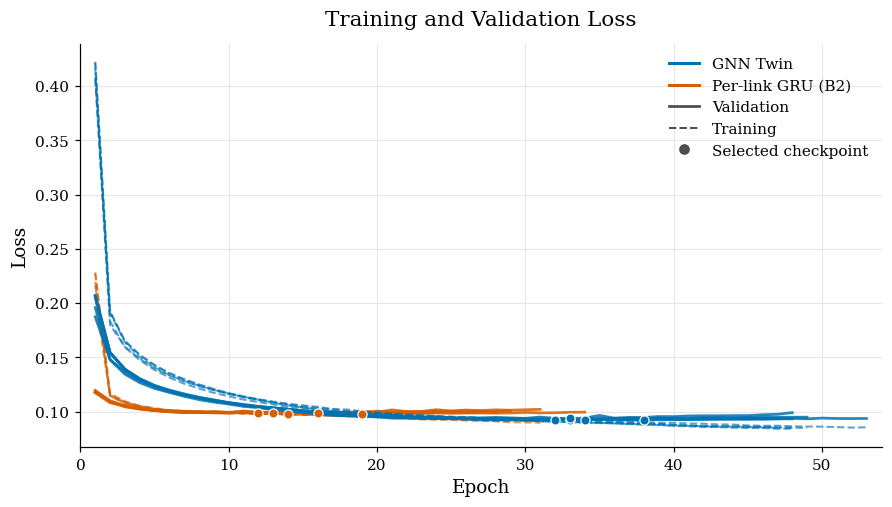

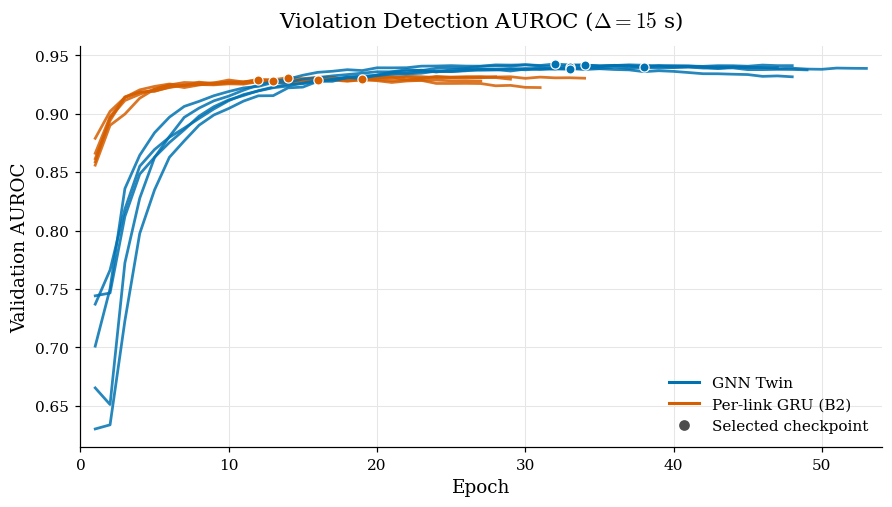

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

style = {
    "GNNTwin": {"color": "#0072B2", "label": "GNN Twin"},
    "LinkGRU": {"color": "#D55E00", "label": "Per-link GRU (B2)"},
}

def format_axis(ax):
    ax.set_xlabel("Epoch", fontsize=12)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(True, color="0.9", linewidth=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.margins(x=0.02)

model_handles = [
    Line2D([0], [0], color=s["color"], lw=2, label=s["label"])
    for s in style.values()
]

# 1. Training and validation loss
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)

for mname in ("LinkGRU", "GNNTwin"):
    for ck in CKPT[mname]:
        h = ck["hist"]
        ep = np.arange(1, len(h["val_loss"]) + 1)
        train_ep = np.arange(1, len(h["train_loss"]) + 1)
        b = ck["best_epoch"]
        color = style[mname]["color"]

        ax.plot(
            ep, h["val_loss"],
            color=color, ls="-", lw=1.8, alpha=0.85,
        )
        ax.plot(
            train_ep, h["train_loss"],
            color=color, ls="--", lw=1.3, alpha=0.65,
        )
        ax.plot(
            b, h["val_loss"][b - 1],
            marker="o", linestyle="none", color=color,
            ms=6, markeredgecolor="white", markeredgewidth=0.8,
            zorder=5,
        )

format_axis(ax)
ax.set_ylabel("Loss", fontsize=12)
ax.set_title("Training and Validation Loss", fontsize=14, pad=12)

loss_handles = model_handles + [
    Line2D([0], [0], color="0.3", lw=1.8, ls="-", label="Validation"),
    Line2D([0], [0], color="0.3", lw=1.3, ls="--", label="Training"),
    Line2D(
        [0], [0], color="0.3", marker="o", linestyle="none",
        ms=6, label="Selected checkpoint",
    ),
]
ax.legend(handles=loss_handles, fontsize=10, frameon=False)

fig.savefig(FIG / "training_loss.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. Validation AUROC
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)

for mname in ("LinkGRU", "GNNTwin"):
    for ck in CKPT[mname]:
        h = ck["hist"]
        ep = np.arange(1, len(h["val_auroc"]) + 1)
        b = ck["best_epoch"]
        color = style[mname]["color"]

        ax.plot(
            ep, h["val_auroc"],
            color=color, lw=1.8, alpha=0.85,
        )
        ax.plot(
            b, h["val_auroc"][b - 1],
            marker="o", linestyle="none", color=color,
            ms=6, markeredgecolor="white", markeredgewidth=0.8,
            zorder=5,
        )

format_axis(ax)
ax.set_ylabel("Validation AUROC", fontsize=12)
ax.set_title(
    r"Violation Detection AUROC ($\Delta = 15$ s)",
    fontsize=14, pad=12,
)
ax.legend(
    handles=model_handles + [loss_handles[-1]],
    loc="lower right", fontsize=10, frameon=False,
)

fig.savefig(FIG / "training_auroc.png", dpi=300, bbox_inches="tight")
plt.show()

### Hyperparameter search (results/figs/tuning.png)

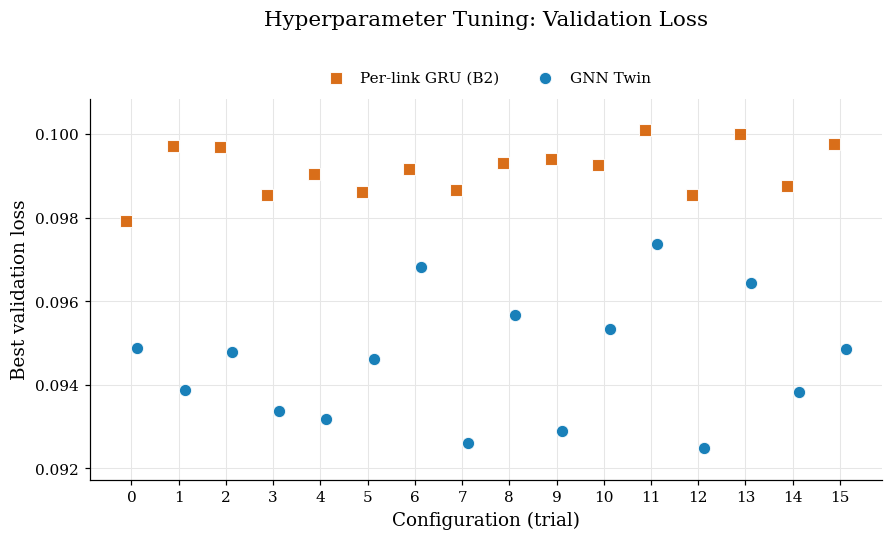

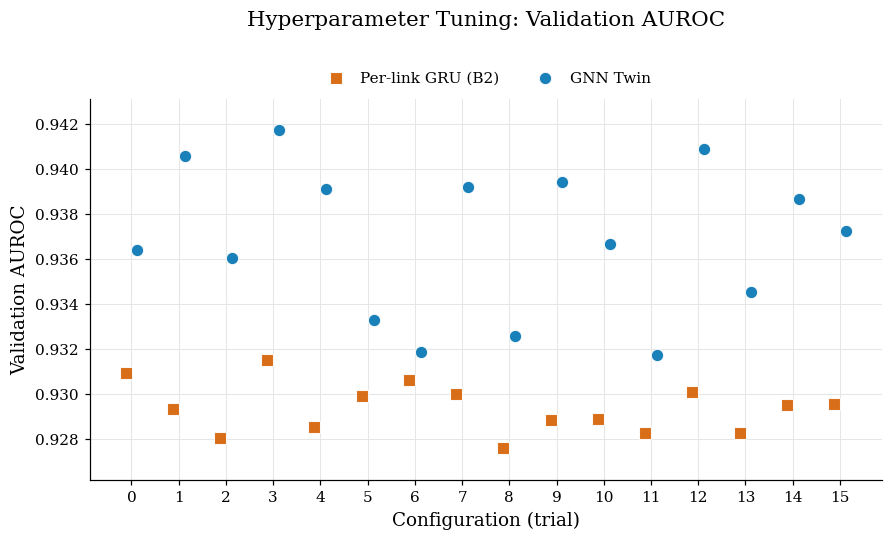

hidden  layers  heads  gru  gru_layers  dropout      lr  batch  \
model   trial                                                                   
LinkGRU 0          32       2      2   64           1      0.0  0.0010     64   
        12         64       3      2   64           1      0.1  0.0003    128   
        3          96       3      2  128           1      0.0  0.0003    256   
        5          96       3      2  128           2      0.0  0.0003     64   
        7          32       3      2  128           1      0.1  0.0020    256   
GNNTwin 12         64       3      2   64           1      0.1  0.0003    128   
        7          32       3      2  128           1      0.1  0.0020    256   
        9          64       3      2  128           2      0.0  0.0020    128   
        4          32       2      4   64           2      0.1  0.0030    256   
        3          96       3      2  128           1      0.0  0.0003    256   

                     wd  params  best_epoch  epochs_run  val_loss  val_auroc  \
model   trial                                                                  
LinkGRU 0      0.000010   34038          13          28  0.097917   0.930921   
        12     0.000010   78070          43          58  0.098528   0.930061   
        3      0.000100  210230          38          53  0.098529   0.931485   
        5      0.000001  309302          13          28  0.098608   0.929888   
        7      0.000010   89782          16          31  0.098649   0.929964   
GNNTwin 12     0.000010   78454          34          49  0.092483   0.940895   
        7      0.000010   89974          15          30  0.092606   0.939191   
        9      0.000010  241270           8          23  0.092898   0.939411   
        4      0.000001   86518          13          28  0.093183   0.939079   
        3      0.000100  210806          39          54  0.093370   0.941711   

               seconds  
model   trial           
LinkGRU 0         16.2  
        12        43.1  
        3         73.2  
        5         54.3  
        7         24.8  
GNNTwin 12        63.6  
        7         36.7  
        9         50.1  
        4         35.2  
        3        118.0

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

style = {
    "LinkGRU": {
        "color": "#D55E00",
        "marker": "s",
        "label": "Per-link GRU (B2)",
    },
    "GNNTwin": {
        "color": "#0072B2",
        "marker": "o",
        "label": "GNN Twin",
    },
}

FIG.mkdir(parents=True, exist_ok=True)

plots = [
    (
        "val_loss",
        "Best validation loss",
        "Hyperparameter Tuning: Validation Loss",
        "tuning_loss.png",
    ),
    (
        "val_auroc",
        "Validation AUROC",
        "Hyperparameter Tuning: Validation AUROC",
        "tuning_auroc.png",
    ),
]

trials = sorted(set().union(
    *(TUNING[m]["trial"].tolist() for m in style)
))

for metric, ylabel, title, filename in plots:
    fig, ax = plt.subplots(
        figsize=(8, 4.8),
        constrained_layout=True,
    )

    for j, mname in enumerate(("LinkGRU", "GNNTwin")):
        t = TUNING[mname].sort_values("trial")
        s = style[mname]

        ax.scatter(
            t["trial"] + (j - 0.5) * 0.25,
            t[metric],
            marker=s["marker"],
            s=65,
            color=s["color"],
            edgecolors="white",
            linewidths=0.7,
            alpha=0.9,
            label=s["label"],
            zorder=3,
        )

    ax.set_xlabel("Configuration (trial)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)

    # Leave space between the title and plot for the legend.
    ax.set_title(title, fontsize=14, pad=48)

    # Center the legend above the axes, outside the data area.
    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=2,
        fontsize=10,
        frameon=False,
        columnspacing=2,
        handletextpad=0.6,
        borderaxespad=0,
    )

    # Thin tick labels when there are many trials.
    step = max(1, (len(trials) + 19) // 20)
    ax.set_xticks(trials[::step])
    ax.tick_params(axis="both", labelsize=10)

    ax.grid(True, color="0.9", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(x=0.05, y=0.1)

    fig.savefig(
        FIG / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )
    plt.show()

# Display the first five rows for each model.
pd.concat(
    {m: TUNING[m].head(5).set_index("trial") for m in TUNING},
    names=["model"],
)

## Package outputs
Zips models, predictions, tables, and figures into `twinguard_outputs.zip` (on Kaggle: download it from the *Output* panel,
then unzip it in the project folder so that `results/` is replaced).

In [28]:
import shutil
with open(RES / "run_info.json", "w") as f:
    json.dump({"environment": "Kaggle" if KAGGLE else "local", "device": str(DEVICE),
               "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
               "torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
               "seeds": SEEDS, "best_hp": BEST_HP, "fixed": FIXED, "n_trials": len(CONFIGS), "n_boot": N_BOOT, "smoke": SMOKE}, f, indent=1)
zip_path = shutil.make_archive(str(ROOT / "twinguard_outputs"), "zip", root_dir=RES.parent, base_dir=RES.name)
print("packaged:", zip_path, f"({Path(zip_path).stat().st_size / 1e6:.1f} MB)")

packaged: /kaggle/working/twinguard_outputs.zip (241.9 MB)


## Inference cost per decision epoch (Section 6.7)
Latency of one decision epoch (one 5-min window, all 13 links and 3 horizons) on 1 and 4 CPU threads and on the GPU,
throughput, model size, and memory, for the per-link GRU, one twin member, and the five-member twin ensemble.

In [33]:
import os, io, gc, json, time, copy, platform, threading
import numpy as np, pandas as pd, torch, torch.nn as nn, psutil

WARMUP, REPEATS, THROUGHPUT_BATCH = 20, 200, 256
PROC = psutil.Process()
BENCH_X = torch.from_numpy(SPL["test_D1"]["X"][:THROUGHPUT_BATCH])
A_T_ORIG = A_T
n_params = lambda m: sum(p.numel() for p in m.parameters())

class PeakRSS:
    def __enter__(self):
        gc.collect(); self.base = PROC.memory_info().rss; self.peak = self.base; self._run = True
        self._t = threading.Thread(target=self._sample, daemon=True); self._t.start(); return self
    def _sample(self):
        while self._run:
            self.peak = max(self.peak, PROC.memory_info().rss); time.sleep(0.002)
    def __exit__(self, *a):
        self._run = False; self._t.join(); self.delta_mb = (self.peak - self.base) / 2**20

def model_mb(models):
    buf = io.BytesIO()
    for m in models: torch.save(m.state_dict(), buf)
    return buf.tell() / 2**20

def run(models, x):
    with torch.inference_mode():
        return [m(x) for m in models]

def bench(name, models, device, threads=None):
    global A_T
    A_T = A_T_ORIG.to(device)                      # the graph-attention mask must live on the same device
    if device.type == "cpu": torch.set_num_threads(threads)
    ms = [copy.deepcopy(m).to(device).eval() for m in models]
    x1, xb = BENCH_X[:1].to(device), BENCH_X.to(device)
    sync = torch.cuda.synchronize if device.type == "cuda" else (lambda: None)
    for _ in range(WARMUP): run(ms, x1)
    sync()
    if device.type == "cuda": torch.cuda.reset_peak_memory_stats()
    lat = []
    cpu0, wall0 = PROC.cpu_times(), time.perf_counter()
    with PeakRSS() as mem:
        for _ in range(REPEATS):
            t = time.perf_counter(); run(ms, x1); sync(); lat.append((time.perf_counter() - t) * 1e3)
        wall = time.perf_counter() - wall0; cpu1 = PROC.cpu_times()
        t, n = time.perf_counter(), 0
        while time.perf_counter() - t < 2.0:
            run(ms, xb); sync(); n += len(xb)
        thr = n / (time.perf_counter() - t)
    busy = ((cpu1.user - cpu0.user) + (cpu1.system - cpu0.system)) / wall
    p95 = float(np.percentile(lat, 95))
    row = {"model": name, "device": "GPU" if device.type == "cuda" else f"CPU, {threads} thread(s)",
           "params": sum(n_params(m) for m in models), "size_MB": round(model_mb(models), 2),
           "latency_ms_median": round(float(np.median(lat)), 3), "latency_ms_p95": round(p95, 3),
           "throughput_windows_s": round(thr), "cpu_cores_busy": round(busy, 2), "ram_peak_MB": round(mem.delta_mb, 1),
           "gpu_mem_peak_MB": round(torch.cuda.max_memory_allocated() / 2**20, 1) if device.type == "cuda" else None,
           "share_of_15s_budget_%": round(100 * p95 / 15000, 4)}
    del ms; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    return row

class Persistence(nn.Module):
    def forward(self, x): return x[:, -1]

CANDIDATES = [("B1 Persistence", [Persistence()]),
              ("B2 Per-link GRU", TRAINED["LinkGRU"][:1]),
              ("GNN twin (1 model)", TRAINED["GNNTwin"][:1]),
              (f"GNN twin ensemble ({len(TRAINED['GNNTwin'])} models)", TRAINED["GNNTwin"])]
SETTINGS = [(torch.device("cpu"), 1), (torch.device("cpu"), 4)]
if torch.cuda.is_available(): SETTINGS.append((torch.device("cuda"), None))

info = {"cpu": platform.processor() or platform.machine(), "logical_cpus": os.cpu_count(),
        "ram_total_GB": round(psutil.virtual_memory().total / 2**30, 1),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, "torch": torch.__version__}
print("hardware:", info)
rss_loaded = PROC.memory_info().rss / 2**20
try:
    rows = [bench(name, models, dev, th) for dev, th in SETTINGS for name, models in CANDIDATES]
finally:
    A_T = A_T_ORIG
    torch.set_num_threads(min(4, os.cpu_count()))
INFER = pd.DataFrame(rows)
INFER.to_csv(RES / "inference_benchmark.csv", index=False)
with open(RES / "inference_hardware.json", "w") as f:
    json.dump({**info, "process_rss_MB_with_models_loaded": round(rss_loaded)}, f, indent=1)
print(f"process memory with all models and data loaded: {rss_loaded:.0f} MB")
INFER


hardware: {'cpu': 'x86_64', 'logical_cpus': 4, 'ram_total_GB': 31.3, 'gpu': 'Tesla T4', 'torch': '2.11.0+cu128'}
process memory with all models and data loaded: 2809 MB


,model,device,params,size_MB,latency_ms_median,latency_ms_p95,throughput_windows_s,cpu_cores_busy,ram_peak_MB,gpu_mem_peak_MB,share_of_15s_budget_%
0,B1 Persistence,"CPU, 1 thread(s)",0,0.00,0.012,0.013,17795482,1.01,0.0,NaN,0.0001
1,B2 Per-link GRU,"CPU, 1 thread(s)",34038,0.14,1.488,1.795,1120,1.01,113.6,NaN,0.0120
2,GNN twin (1 model),"CPU, 1 thread(s)",78454,0.31,3.313,3.707,218,1.03,188.8,NaN,0.0247
3,GNN twin ensemble (5 models),"CPU, 1 thread(s)",392270,1.53,17.074,19.350,43,1.03,162.1,NaN,0.1290
4,B1 Persistence,"CPU, 4 thread(s)",0,0.00,0.012,0.015,19377657,1.02,0.0,NaN,0.0001
5,B2 Per-link GRU,"CPU, 4 thread(s)",34038,0.14,2.170,2.533,2246,3.22,87.8,NaN,0.0169
6,GNN twin (1 model),"CPU, 4 thread(s)",78454,0.31,3.918,4.517,447,3.47,189.2,NaN,0.0301
7,GNN twin ensemble (5 models),"CPU, 4 thread(s)",392270,1.53,19.652,21.522,88,3.86,162.5,NaN,0.1435
8,B1 Persistence,GPU,0,0.00,0.019,0.034,10634041,1.02,0.0,95.1,0.0002
9,B2 Per-link GRU,GPU,34038,0.14,0.826,0.986,37914,1.04,0.0,433.6,0.0066
